In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency
from scipy import stats

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(r"C:\Users\rkham\OneDrive\Desktop\amz_uk_price_prediction_dataset.csv\amz_uk_price_prediction_dataset.csv")

df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [3]:
# Number of best-sellers and non-best-sellers per category
crosstab = pd.crosstab(df['category'], df['isBestSeller'])

display(crosstab.head())

# Proportion of best-sellers in each category
bestseller_proportion = (
    df.groupby('category')['isBestSeller']
    .mean()
    .sort_values(ascending=False)
)

display(bestseller_proportion.head(10))

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3


category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057686
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
Billiard, Snooker & Pool          0.032129
Pet Supplies                      0.030200
Home Brewing & Wine Making        0.028455
Mirrors                           0.028000
Wind Instruments                  0.028000
Name: isBestSeller, dtype: float64

Explanation: Since True = 1 and False = 0, taking the mean gives the proportion of best-sellers.

In [4]:
chi2, p, dof, expected = chi2_contingency(crosstab)

print("Chi-square:", chi2)
print("P-value:", p)
print("Degrees of freedom:", dof)

Chi-square: 36540.20270061387
P-value: 0.0
Degrees of freedom: 295


In [5]:
n = crosstab.sum().sum()
r, k = crosstab.shape

cramers_v = np.sqrt(chi2 / (n * min(r - 1, k - 1)))

print("Cramér's V:", cramers_v)

Cramér's V: 0.1222829439760564


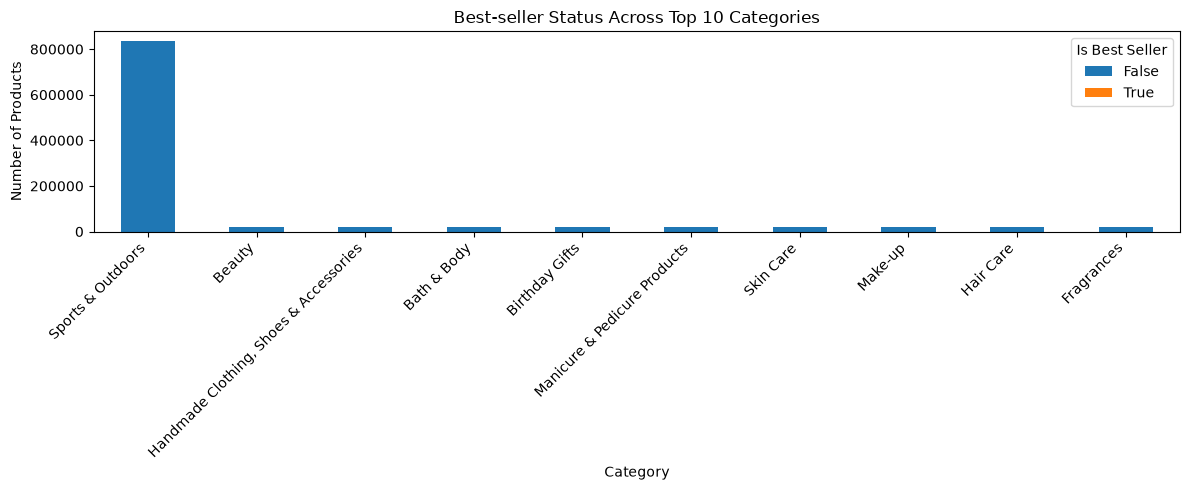

In [6]:
top_10 = df['category'].value_counts().head(10).index

crosstab.loc[top_10].plot(
    kind='bar',
    stacked=True,
    figsize=(12, 5)
)

plt.title("Best-seller Status Across Top 10 Categories")
plt.xlabel("Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha='right')
plt.legend(title="Is Best Seller")
plt.tight_layout()
plt.show()

In [ ]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df_clean = df[
    (df['price'] >= lower) &
    (df['price'] <= upper)
].copy()

print("Original rows:", len(df))
print("Rows without outliers:", len(df_clean))


Original rows: 2443651
Rows without outliers: 2115963


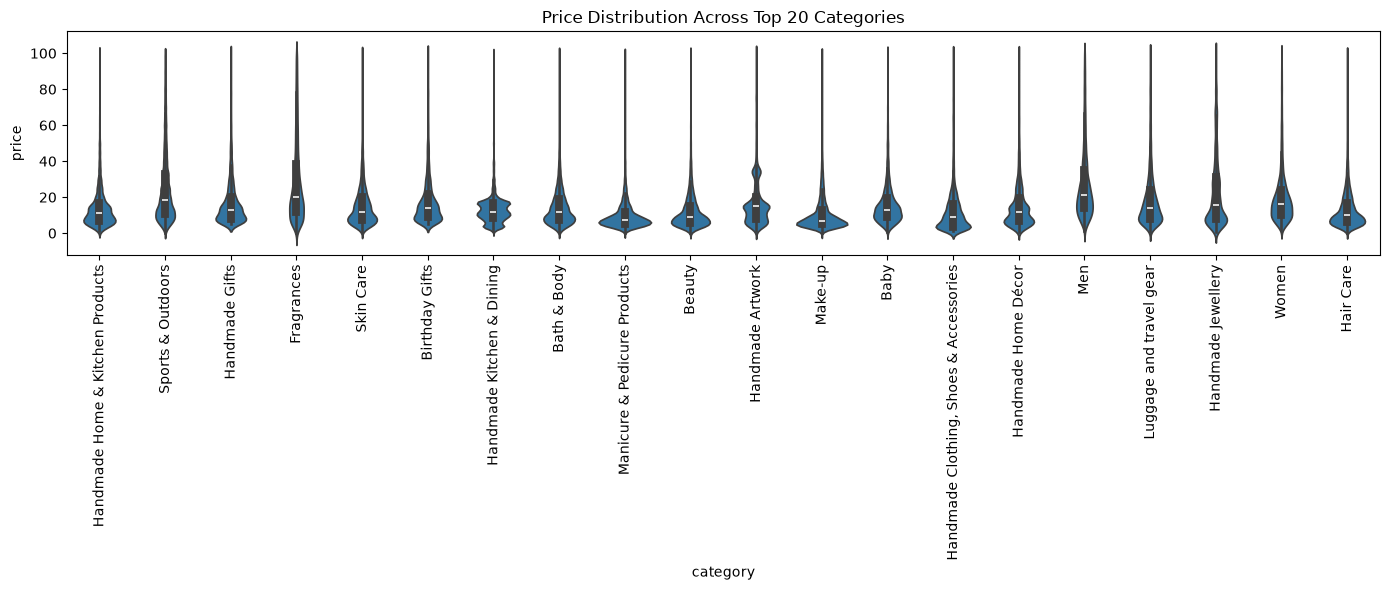

In [8]:
top_20 = df_clean['category'].value_counts().head(20).index

plt.figure(figsize=(14, 6))

sns.violinplot(
    data=df_clean[df_clean['category'].isin(top_20)],
    x='category',
    y='price'
)

plt.xticks(rotation=90)
plt.title("Price Distribution Across Top 20 Categories")
plt.tight_layout()
plt.show()

In [9]:
median_prices = (
    df_clean.groupby('category')['price']
    .median()
    .sort_values(ascending=False)
)

print(median_prices.head(10))

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64


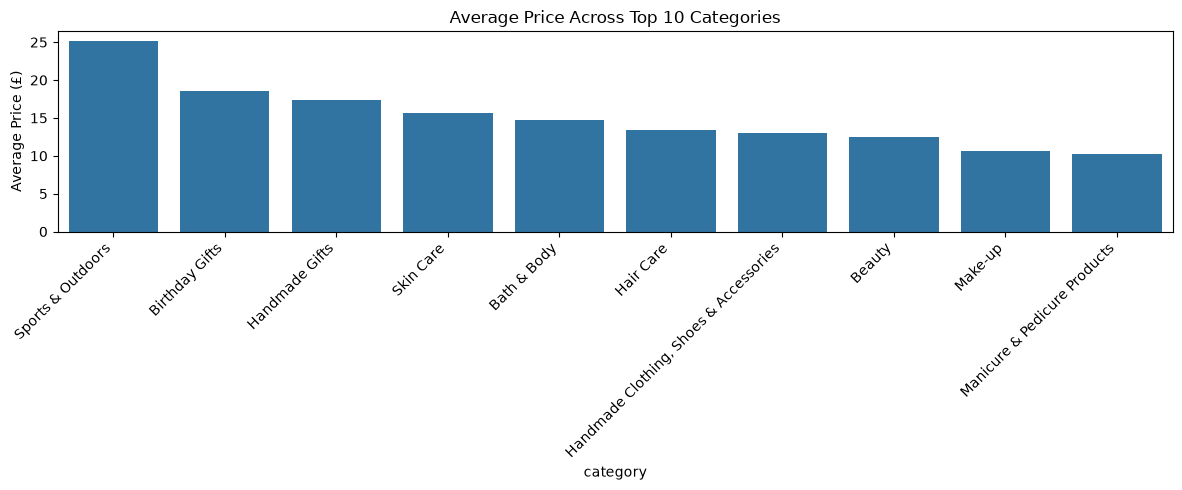

In [10]:
top_10 = df_clean['category'].value_counts().head(10).index

average_prices = (
    df_clean[df_clean['category'].isin(top_10)]
    .groupby('category')['price']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 5))

sns.barplot(
    x=average_prices.index,
    y=average_prices.values
)

plt.xticks(rotation=45, ha='right')
plt.title("Average Price Across Top 10 Categories")
plt.ylabel("Average Price (£)")
plt.tight_layout()
plt.show()

In [11]:
mean_prices = (
    df_clean.groupby('category')['price']
    .mean()
    .sort_values(ascending=False)
)

print(mean_prices.head(10))

category
Motherboards         68.772432
Boxing Shoes         67.417803
Desktop PCs          66.915562
Tablets              66.552971
Graphics Cards       65.103509
Digital Frames       60.745129
Streaming Clients    60.241803
Hockey Shoes         60.094796
Computer Cases       58.339884
Skiing Poles         57.867770
Name: price, dtype: float64


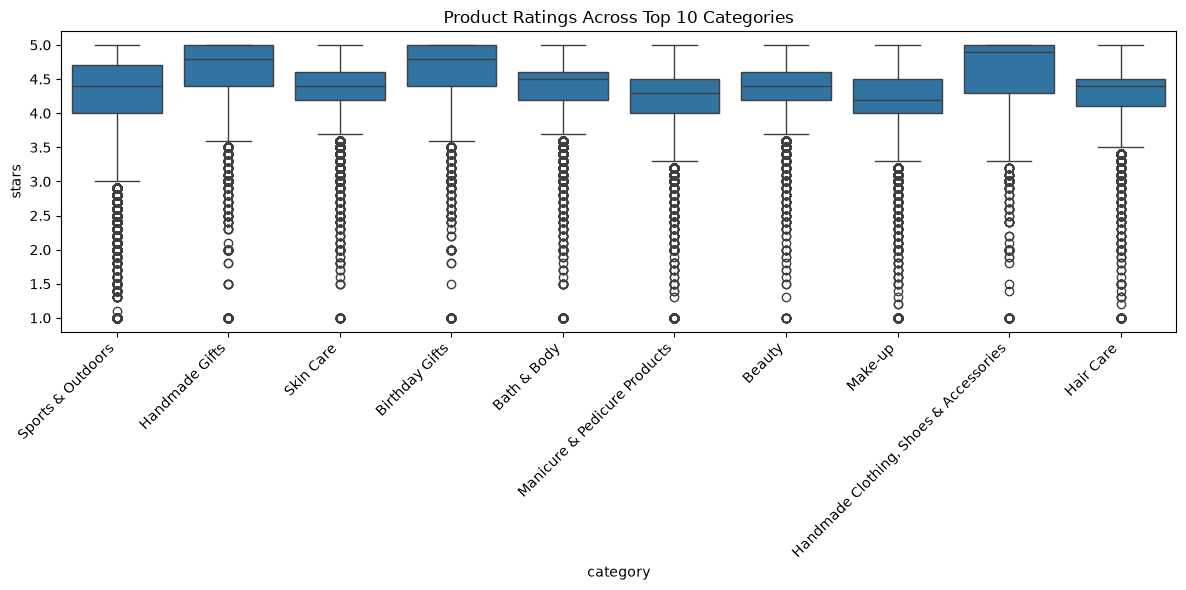

In [12]:
top_10 = df_clean['category'].value_counts().head(10).index

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_clean[
        df_clean['category'].isin(top_10) &
        (df_clean['reviews'] > 0)
    ],
    x='category',
    y='stars'
)

plt.xticks(rotation=45, ha='right')
plt.title("Product Ratings Across Top 10 Categories")
plt.tight_layout()
plt.show()

In [13]:
df_rated = df_clean[df_clean['reviews'] > 0].copy()

correlation = df_rated['price'].corr(df_rated['stars'])

print("Pearson correlation:", correlation)

Pearson correlation: 0.006744508067157899


In [14]:
r, p = stats.pearsonr(df_rated['price'], df_rated['stars'])

print("Correlation:", r)
print("P-value:", p)

Correlation: 0.006744508067157991
P-value: 1.0813032347767428e-12


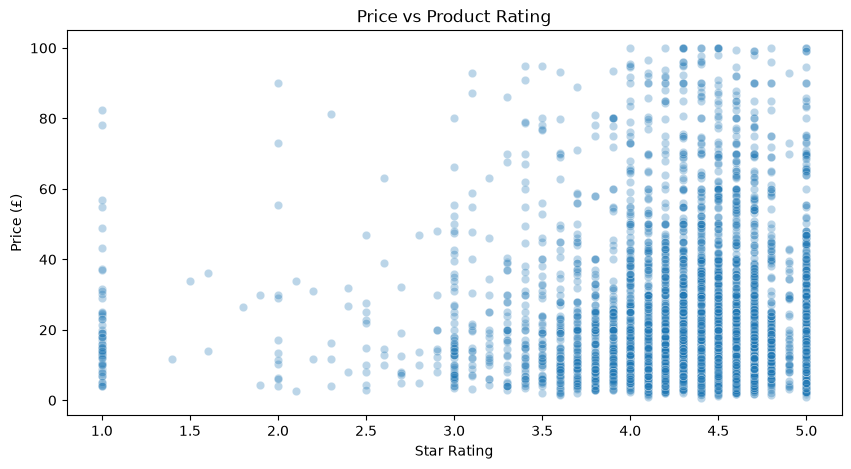

In [15]:
sample = df_rated.sample(
    n=min(5000, len(df_rated)),
    random_state=42
)

plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=sample,
    x='stars',
    y='price',
    alpha=0.3
)

plt.title("Price vs Product Rating")
plt.xlabel("Star Rating")
plt.ylabel("Price (£)")
plt.show()

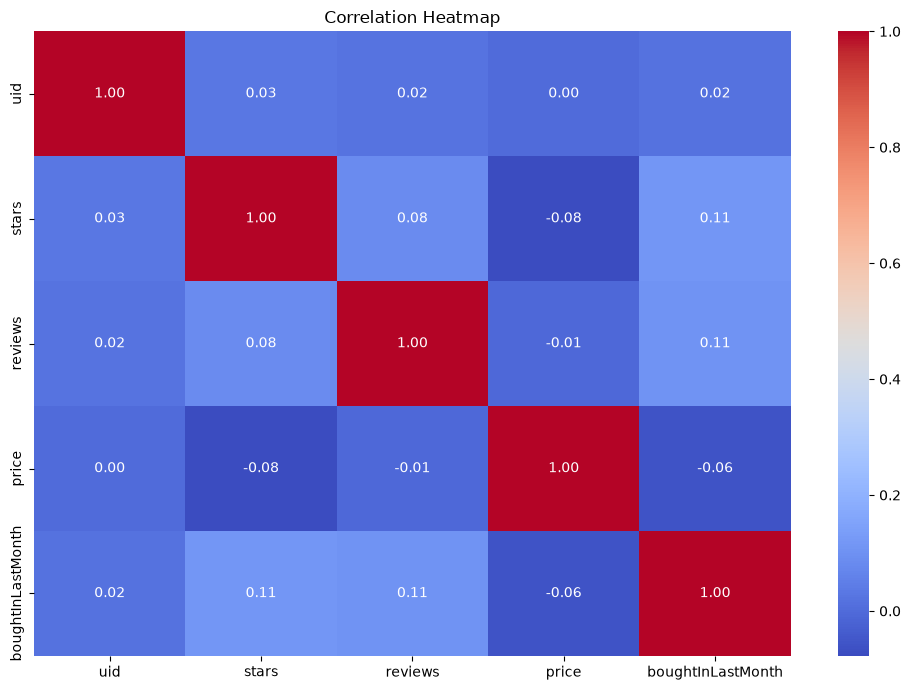

In [16]:
numeric_df = df_clean.select_dtypes(include='number')

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

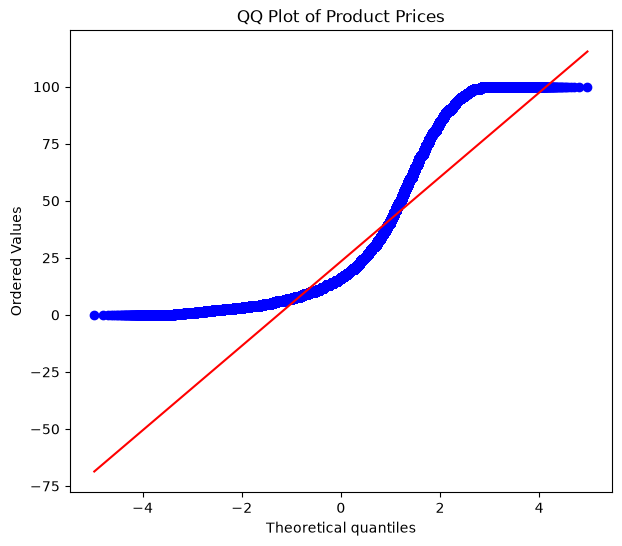

In [17]:
plt.figure(figsize=(7, 6))

stats.probplot(
    df_clean['price'],
    dist='norm',
    plot=plt
)

plt.title("QQ Plot of Product Prices")
plt.show()

# Amazon UK — Bivariate EDA Business Report

## 1. Best-Seller Trends

The analysis shows that sports and outdoors has the highest proportion of best-selling products.

A chi-square p-value of 0 indicates that the observed data is highly unlikely under the null hypothesis, suggesting that there is a statistically significant association between the variables being tested. 

Cramér's V: 0.1222829439760564 suggests that this relationship is indicates a weak association between the two categorical variables being analyzed. Values closer to 0 suggest little to no relationship, while values approaching 1 indicate a stronger association.

**Business implication:** Product category may be associated with best-seller status. Businesses can use this information to investigate categories with a relatively high proportion of best-selling listings.

## 2. Pricing Across Categories

After removing price outliers using the IQR method, following products remained in the dataset:
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33

The category with the highest median price was Desktop PCs , while Motherboards had the highest average price.

The violin plots show similar pricing distributions across categories.

**Business implication:** Pricing strategies should account for differences between product categories rather than using a single approach for all products.

## 3. Product Ratings

The category with the highest median customer rating was Handmade gifts.

The box plots reveal low variation in ratings across categories.

**Business implication:** Categories with consistently high customer ratings may provide useful benchmarks for customer satisfaction.

## 4. Relationship Between Prices and Ratings

The Pearson correlation between product price and customer rating was 0.006744508067157899, indicating a weak relationship.

The scatter plot shows that the products pricing between 20-40 pounds get reviewed much more often, but there is no visible correlation between the reviews and prices.

The QQ plot suggests that product prices do not follow an approximately normal distribution.

**Business implication:** Price alone may not explain customer satisfaction. Other factors, including product quality and customer expectations, should also be considered.

## Conclusion

The analysis identifies differences in best-seller prevalence, pricing, and customer ratings across Amazon UK product categories. These findings can support product positioning, pricing decisions, and further market research.